In [1]:
import pandas as pd
import sqlite3

In [2]:
conn= sqlite3.connect('../data/checking-logs.sqlite')

In [3]:
views = pd.read_sql("""
SELECT
    date(datetime) AS date,
    COUNT(*) AS views
FROM pageviews
WHERE uid LIKE 'user_%'
GROUP BY date
""", conn)

commits = pd.read_sql("""
SELECT
    date(timestamp) AS date,
    COUNT(*) AS commits
FROM checker
WHERE uid LIKE 'user_%'
GROUP BY date
""", conn)

In [4]:
df = views.merge(commits, on='date', how='inner')
df['date'] = pd.to_datetime(df['date'])
df = df.set_index('date')

/tmp/ipykernel_331758/295376563.py:2: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=90)


[Text(18369.0, 0, '2020-04-17'),
 Text(18373.0, 0, '2020-04-21'),
 Text(18377.0, 0, '2020-04-25'),
 Text(18381.0, 0, '2020-04-29'),
 Text(18383.0, 0, '2020-05-01'),
 Text(18387.0, 0, '2020-05-05'),
 Text(18391.0, 0, '2020-05-09'),
 Text(18395.0, 0, '2020-05-13'),
 Text(18399.0, 0, '2020-05-17'),
 Text(18403.0, 0, '2020-05-21')]

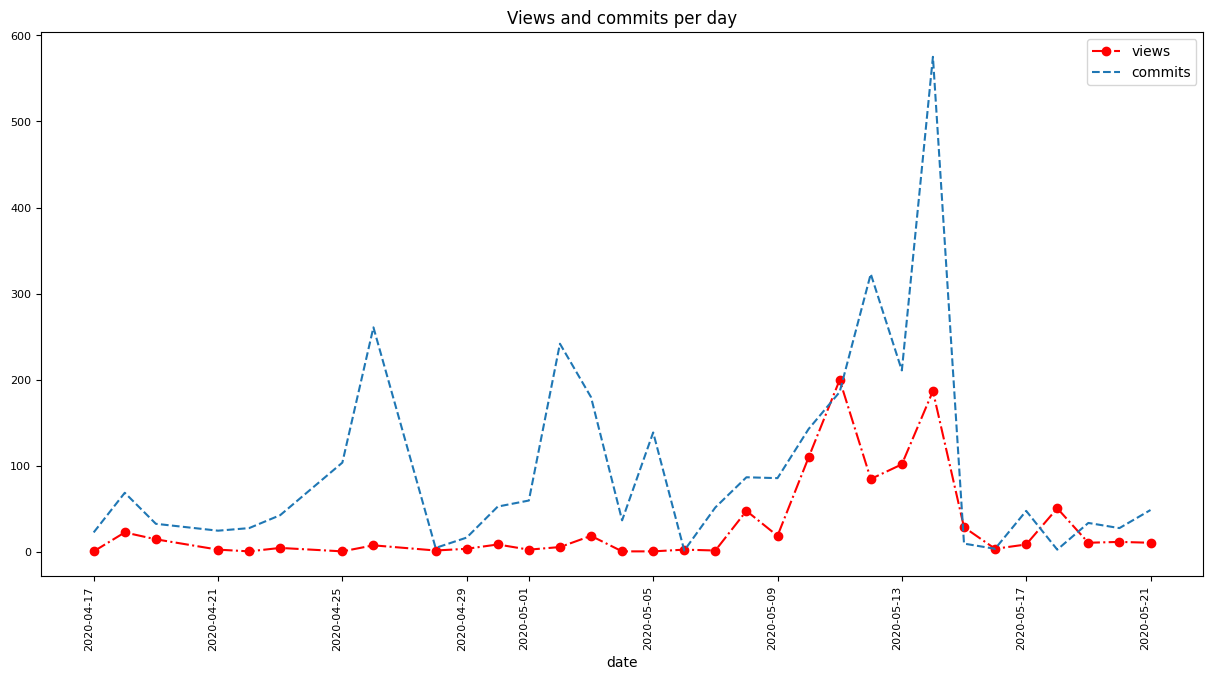

In [5]:
ax=df.plot(figsize=(15, 8), fontsize=8, style=['r-.o','--'], title='Views and commits per day')
ax.set_xticklabels(ax.get_xticklabels(), rotation=90)

In [6]:
conn.close()

In [7]:
answer = (df['views'] > 150).sum()
answer


np.int64(2)

How many times was the number of views larger than 150?

The answer is 2